# Exploratory Data Analysis — Kathmandu Hourly PM2.5
**Author:** Raheem  **Course:** TECH405

**Project goal:** forecast hourly PM2.5 concentration in Kathmandu with an LSTM.
**Dataset:** `kathmandu_pm25_hourly.csv`

This notebook covers **Part A** (mandatory items for every project) and **Part B** (the time-series items, since this is a time-series project).

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import MSTL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# --- consistent, quiet chart style ---
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (12, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 1.2,
    "legend.frameon": False,
})

DATA = "kathmandu_pm25_hourly.csv"
TARGET_STATION = "Embassy Kathmandu"   # station the LSTM will be trained on
NPT = "Asia/Kathmandu"                 # Nepal time, UTC+05:45

---
# Part A — Mandatory

## A1. Dataset card

In [2]:
raw = pd.read_csv(DATA)
raw["time_utc"] = pd.to_datetime(raw["time_utc"], utc=True)

card = {
    "File": DATA,
    "Size on disk": f"{os.path.getsize(DATA)/1024**2:.1f} MB",
    "Samples (rows)": f"{len(raw):,}",
    "Columns": ", ".join(raw.columns),
    "Monitoring stations": raw["station"].nunique(),
    "Time span (UTC)": f"{raw.time_utc.min():%Y-%m-%d} → {raw.time_utc.max():%Y-%m-%d}",
    "Sampling frequency": "1 hour",
    f"Rows for target station ({TARGET_STATION})": f"{(raw.station == TARGET_STATION).sum():,}",
}
pd.Series(card, name="value").to_frame()

,value
File,kathmandu_pm25_hourly.csv
Size on disk,28.9 MB
Samples (rows),"341,633"
Columns,"time_utc, station, location_id, lat, lon, pm25"
Monitoring stations,55
Time span (UTC),2017-03-02 → 2026-10-03
Sampling frequency,1 hour
Rows for target station (Embassy Kathmandu),"55,649"


| Field | Details |
|---|---|
| **Source** | Downloaded from **OpenAQ**, which collects open air-quality data: <https://openaq.org> (explorer: <https://explore.openaq.org>). The `location_id` column holds OpenAQ location IDs. For example, the target station is <https://explore.openaq.org/locations/> + its `location_id`. |
| **Original providers** | *Embassy Kathmandu* and *Phora Durbar Kathmandu*: U.S. Department of State / U.S. EPA **AirNow** reference monitors (Met One BAM-1020 beta-attenuation). *“… – GD Labs”* stations (SC-xx): a network of low-cost optical sensors. *CEN-SR-xx*: Clean Energy Nepal low-cost sensors. *ICE Labs* and others: university or community low-cost sensors. |
| **Licence** | OpenAQ redistributes each provider's data under that provider's licence. AirNow / U.S. Government data is **public domain**. Most other OpenAQ providers use **CC BY 4.0** (credit required). Check each station's licence on its OpenAQ page before republishing. |
| **Size** | ~29 MB CSV, 341,633 rows × 6 columns (`time_utc, station, location_id, lat, lon, pm25`) |
| **Samples** | One row = one station-hour. PM2.5 mass concentration in µg/m³ (hourly average). |
| **How it was collected** | Fixed outdoor monitors in the Kathmandu Valley. The reference monitors (Embassy, Phora Durbar) use beta-attenuation (BAM). The rest are low-cost laser-scattering sensors. OpenAQ ingests their feeds and publishes hourly averages, which were exported with timestamps in UTC. |
| **Known limitations** | (1) Large **gaps**: rows exist only for hours that were reported, so missing hours are simply absent. (2) **Instrument ceiling**: the BAM reports 985 µg/m³ when it saturates or errors. (3) **Low-cost sensors** over-read in humid air (the monsoon) and are not calibrated against the reference monitor. (4) Most stations exist only from Sept 2025 on. Only the two U.S. Embassy monitors cover several years. (5) A few stations moved (several coordinate sets per station). (6) Timestamps are UTC, but pollution follows *local* (UTC+05:45) human activity. |

## A2. Load the data: shape, dtypes, file structure, 5 random samples

In [3]:
print("Shape:", raw.shape)
print("\nDtypes:")
print(raw.dtypes)
print("\nMemory:", f"{raw.memory_usage(deep=True).sum()/1024**2:.1f} MB")

Shape: (341633, 6)

Dtypes:
time_utc       datetime64[us, UTC]
station                        str
location_id                  int64
lat                        float64
lon                        float64
pm25                       float64
dtype: object

Memory: 23.4 MB


In [4]:
# File structure: long ("tidy") format. One row per (station, hour).
raw.sample(5, random_state=42)

,time_utc,station,location_id,lat,lon,pm25
199444,2026-02-12 21:00:00+00:00,Nakhipot (SC-08) - GD Labs,5633032,27.651081,85.317857,71.854167
21537,2026-02-07 03:00:00+00:00,Chhetrapati (SC - 19) - GD Labs,6093432,27.711914,85.306147,182.911333
77688,2020-02-19 11:00:00+00:00,Embassy Kathmandu,3459,27.738703,85.336205,85.000000
129791,2026-07-21 13:00:00+00:00,Golfutar (SC- 17) - GD Labs,6093549,27.748570,85.349052,6.200000
186018,2026-07-16 16:00:00+00:00,Lamtangil (SC-04)- GD Labs,5519358,27.731368,85.336783,15.700000


In [5]:
# Structure per station: coverage and record length
per_station = (raw.groupby("station")
                  .agg(rows=("pm25", "size"),
                       first=("time_utc", "min"), last=("time_utc", "max"),
                       mean_pm25=("pm25", "mean"))
                  .sort_values("rows", ascending=False))
per_station["span_days"] = (per_station["last"] - per_station["first"]).dt.days
per_station["coverage_%"] = (100 * per_station["rows"] / (per_station["span_days"] * 24 + 1)).round(1)
per_station.head(12)

,rows,first,last,mean_pm25,span_days,coverage_%
station,,,,,,
Embassy Kathmandu,55649,2017-03-02 23:00:00+00:00,2026-06-17 18:00:00+00:00,44.964348,3393,68.3
Phora Durbar Kathman,47287,2017-03-02 23:00:00+00:00,2025-03-24 14:00:00+00:00,54.951845,2943,66.9
"Dabali, Handigaun",16133,2024-05-16 03:00:00+00:00,2026-10-03 18:00:00+00:00,42.431736,870,77.3
Chovar (SC - 07) - GD Labs,7866,2025-09-19 00:00:00+00:00,2026-10-03 18:00:00+00:00,43.751488,379,86.5
Golfutar (SC- 17) - GD Labs,7728,2025-10-13 07:00:00+00:00,2026-10-03 18:00:00+00:00,52.616782,355,90.7
Sunakothi (SC - 06) - GD Labs,7417,2025-09-19 00:00:00+00:00,2026-10-02 05:00:00+00:00,41.356513,378,81.7
Sundarighat (SC-23) - GD Labs,7412,2025-10-14 05:00:00+00:00,2026-10-03 18:00:00+00:00,51.511502,354,87.2
Lagankhel (SC - 05) - GD Labs,7344,2025-10-03 00:00:00+00:00,2026-10-03 18:00:00+00:00,51.513306,365,83.8
"Dhathutole, Handigaun",7254,2023-11-25 19:00:00+00:00,2026-06-01 04:00:00+00:00,67.679227,918,32.9


## A3. Missing, duplicate and corrupt entries

The checks run over the whole file and then, more strictly, over the target station's hourly series.

In [6]:
checks = {
    "NaN cells (any column)": int(raw.isna().sum().sum()),
    "Exact duplicate rows": int(raw.duplicated().sum()),
    "Duplicate (station, hour) keys": int(raw.duplicated(["station", "time_utc"]).sum()),
    "Timestamps not on the hour": int((raw.time_utc.dt.minute != 0).sum()),
    "Negative PM2.5": int((raw.pm25 < 0).sum()),
    "PM2.5 == 0 (implausible in Kathmandu)": int((raw.pm25 == 0).sum()),
    "PM2.5 == 985 (BAM ceiling / error code)": int((raw.pm25 == 985).sum()),
    "PM2.5 > 1000 (physically implausible)": int((raw.pm25 > 1000).sum()),
    "Stations with > 1 coordinate pair": int((raw.groupby("station")[["lat", "lon"]].nunique().max(axis=1) > 1).sum()),
    "Stations with < 500 rows (too short to use)": int((per_station.rows < 500).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
NaN cells (any column),0
Exact duplicate rows,0
"Duplicate (station, hour) keys",0
Timestamps not on the hour,0
Negative PM2.5,0
PM2.5 == 0 (implausible in Kathmandu),2873
PM2.5 == 985 (BAM ceiling / error code),47
PM2.5 > 1000 (physically implausible),81
Stations with > 1 coordinate pair,8
Stations with < 500 rows (too short to use),4


In [7]:
# Implicit missing values: hours with no row at all.
def hourly(station):
    s = raw.loc[raw.station == station].set_index("time_utc")["pm25"].sort_index()
    return s.asfreq("h")        # reindex onto a regular hourly grid -> gaps become NaN

emb_raw = hourly(TARGET_STATION)
n_exp, n_obs = len(emb_raw), emb_raw.notna().sum()
print(f"{TARGET_STATION}: {n_exp:,} expected hours, {n_obs:,} present, "
      f"{n_exp - n_obs:,} missing ({100*(n_exp-n_obs)/n_exp:.1f} %)")

# Length of every gap
isna = emb_raw.isna()
gap_id = (isna != isna.shift()).cumsum()
gap_len = isna.groupby(gap_id).sum()
gap_len = gap_len[gap_len > 0]
bins = [0, 1, 3, 6, 24, 24*7, 24*30, 10**6]
labels = ["1 h", "2–3 h", "4–6 h", "7–24 h", "1–7 d", "1–4 wk", "> 1 month"]
gap_table = pd.cut(gap_len, bins=bins, labels=labels).value_counts().sort_index().to_frame("number of gaps")
gap_table["hours lost"] = gap_len.groupby(pd.cut(gap_len, bins=bins, labels=labels)).sum()
gap_table

Embassy Kathmandu: 81,452 expected hours, 55,649 present, 25,803 missing (31.7 %)


,number of gaps,hours lost
pm25,,
1 h,917,917
2–3 h,664,1507
4–6 h,221,1060
7–24 h,222,2921
1–7 d,99,6734
1–4 wk,18,5591
> 1 month,3,7073


In [8]:
# Corrupt values at the target station
e = emb_raw.dropna()
roll_med = emb_raw.rolling(25, center=True, min_periods=6).median()
spike = (emb_raw > 250) & (emb_raw > 4 * roll_med)          # isolated jump, much higher than its 24 h neighbourhood

print("985 µg/m³ ceiling values :", int((e == 985).sum()))
print("Zeros                    :", int((e == 0).sum()))
print("Isolated spikes (>250 and >4× 24h median):", int(spike.sum()))
print("\nMonths in which 985 occurs:", sorted(e[e == 985].index.month.unique()))

985 µg/m³ ceiling values : 32
Zeros                    : 193
Isolated spikes (>250 and >4× 24h median): 83

Months in which 985 occurs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [9]:
def clean_station(s):
    s = s.copy()
    s[s == 985] = np.nan                                     # instrument ceiling / error flag
    s[s <= 0] = np.nan                                       # zero = dropout, not clean air
    s[s > 1000] = np.nan                                     # physically implausible
    med = s.rolling(25, center=True, min_periods=6).median()
    s[(s > 250) & (s > 4 * med)] = np.nan                    # isolated single-hour spikes
    return s

emb = clean_station(emb_raw)
emb_filled = emb.interpolate(method="time", limit=3, limit_area="inside")   # bridge short gaps only
print(f"Removed as corrupt: {int(emb_raw.notna().sum() - emb.notna().sum())} values")
print(f"Filled by ≤3 h interpolation: {int(emb_filled.notna().sum() - emb.notna().sum())} hours")
print(f"Still missing (long gaps, left as NaN): {int(emb_filled.isna().sum()):,} hours")

Removed as corrupt: 276 values
Filled by ≤3 h interpolation: 4308 hours
Still missing (long gaps, left as NaN): 21,771 hours


**What I will do about them**

| Issue | Count | Action |
|---|---|---|
| NaN cells / exact duplicates / duplicate keys | 0 | Nothing needed. Still asserted in the pipeline so a re-download can't add them silently. |
| Missing hours (no row) | about 1/3 of the hours in the target station's span | Reindex to an hourly grid. Linearly interpolate **gaps ≤ 3 h** only. Leave longer gaps as NaN and **never build an LSTM window that crosses one**. |
| 985 µg/m³ | BAM ceiling. Appears even in monsoon months, so it is an error code, not smoke | Set to NaN, then treat like a missing hour. |
| Zeros | BAM dropouts. Kathmandu never has truly 0 µg/m³ air | Set to NaN. |
| > 1000 µg/m³ and isolated one-hour spikes | Mostly at low-cost sensors near brick kilns | Set to NaN. Multi-hour high episodes (festivals, forest fires) are **kept**, because they are real and the model must learn them. |
| Stations moved / < 500 rows | A few | Excluded from multi-station features. Not relevant for the single-station model. |

## A4. Target distribution

This is a **regression** task (target = next-hour PM2.5 in µg/m³), so there are no classes. Two views stand in for a class distribution: the distribution of the continuous value, and its spread across the official **U.S. EPA AQI categories** (2024 PM2.5 breakpoints). The categories show where the model will see few examples.

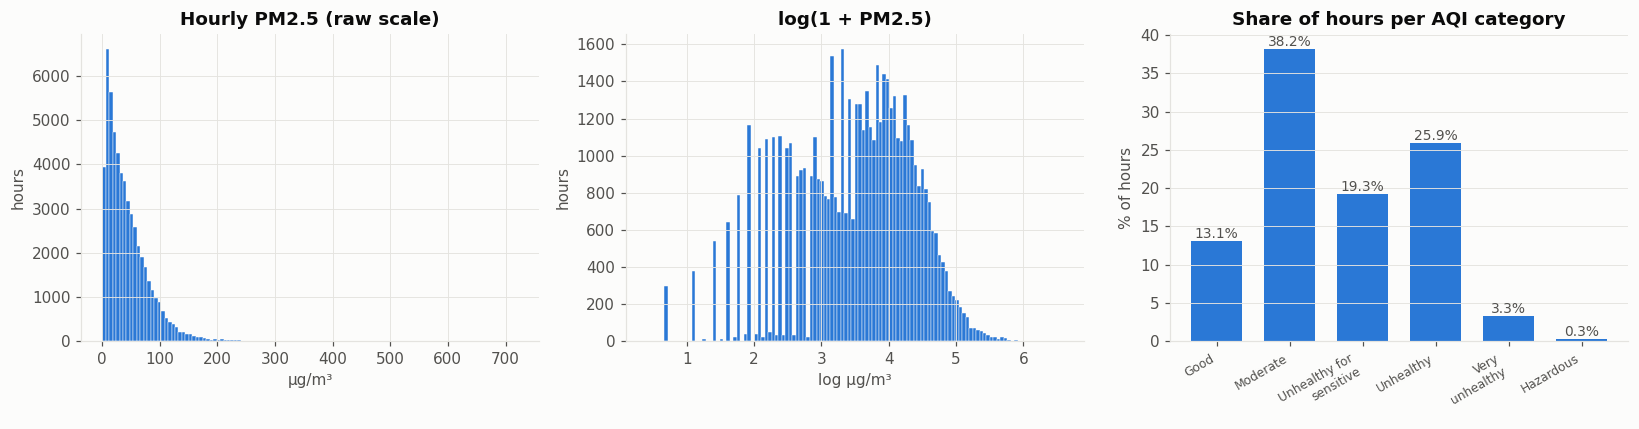

skewness raw = 2.20   skewness log1p = -0.42
count    55373.0
mean        44.1
std         38.1
min          0.5
50%         34.0
90%         92.0
99%        172.3
99.9%      290.6
max        722.0


In [10]:
AQI_BINS   = [0, 9.0, 35.4, 55.4, 125.4, 225.4, np.inf]
AQI_LABELS = ["Good", "Moderate", "Unhealthy for\nsensitive", "Unhealthy", "Very\nunhealthy", "Hazardous"]

y = emb.dropna()
aqi = pd.cut(y, AQI_BINS, labels=AQI_LABELS)
aqi_pct = aqi.value_counts(normalize=True).reindex(AQI_LABELS) * 100

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(y, bins=120, color=BLUE, edgecolor="#fcfcfb", linewidth=0.3)
ax[0].set(title="Hourly PM2.5 (raw scale)", xlabel="µg/m³", ylabel="hours")
ax[1].hist(np.log1p(y), bins=120, color=BLUE, edgecolor="#fcfcfb", linewidth=0.3)
ax[1].set(title="log(1 + PM2.5)", xlabel="log µg/m³", ylabel="hours")
bars = ax[2].bar(AQI_LABELS, aqi_pct.values, color=BLUE, width=0.7)
ax[2].bar_label(bars, fmt="%.1f%%", color=INK2, fontsize=9)
ax[2].set(title="Share of hours per AQI category", ylabel="% of hours")
ax[2].tick_params(axis="x", labelsize=8, rotation=30); ax[2].grid(axis="x", visible=False)
plt.setp(ax[2].get_xticklabels(), ha="right")
plt.tight_layout(); plt.show()

print(f"skewness raw = {y.skew():.2f}   skewness log1p = {np.log1p(y).skew():.2f}")
print(y.describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())

In [11]:
# Imbalance is driven by season: the same category is common in one season and absent in another
season = pd.Series(np.select([y.index.month.isin([12, 1, 2]), y.index.month.isin([3, 4, 5]),
                              y.index.month.isin([6, 7, 8, 9])],
                             ["Winter (Dec–Feb)", "Pre-monsoon (Mar–May)", "Monsoon (Jun–Sep)"],
                             "Post-monsoon (Oct–Nov)"), index=y.index)
ct = (pd.crosstab(season, aqi, normalize="index") * 100).round(1)
ct.columns = [c.replace("\n", " ") for c in ct.columns]
ct

,Good,Moderate,Unhealthy for sensitive,Unhealthy,Very unhealthy,Hazardous
row_0,,,,,,
Monsoon (Jun–Sep),36.2,57.2,5.8,0.7,0.0,0.0
Post-monsoon (Oct–Nov),8.6,52.1,22.9,16.0,0.3,0.0
Pre-monsoon (Mar–May),1.5,31.5,27.6,33.6,4.8,0.8
Winter (Dec–Feb),0.2,13.2,24.4,54.3,7.4,0.4


**Comment on imbalance and its effect on the model**

* The Embassy BAM reports **whole µg/m³**, which is why the low end of the log histogram is spiky. The target is effectively quantised at 1 µg/m³, so errors below about 1 µg/m³ carry no meaning.
* The target is **right-skewed**: most hours sit between about 15 and 80 µg/m³, with a long tail of a few hundred µg/m³. The *Very unhealthy* and *Hazardous* bins hold only a small fraction of the hours, but those are the hours that matter most for public health.
* An LSTM trained with plain MSE on raw values will **regress to the mean**. It will forecast typical hours well and systematically **under-predict pollution peaks**. A few extreme hours will also dominate the gradients.
* The imbalance is **seasonal**: *Good* hours come almost entirely from the monsoon, and *Unhealthy+* hours almost entirely from winter and pre-monsoon. A split that drops a season would hide this.
* **Mitigations:** train on `log1p(PM2.5)` (skew falls from 2.2 to −0.4); consider Huber loss; report error **per AQI category and per season**, not only overall RMSE; and check recall on the hours above 55.4 µg/m³ (*Unhealthy*).

## A5. Train / validation / test split plan

**Plan: chronological (time-based) split on the target station, no shuffling, with a gap between splits.**

| Split | Period (UTC) | Why |
|---|---|---|
| Train | 2017-03-02 → 2023-12-31 | Longest block; covers about 7 full seasonal cycles |
| Validation | 2024-01-01 → 2024-12-31 | One complete year, so every season appears in model selection |
| Test | 2025-01-01 → 2026-06-17 | Most recent data, which is the real deployment scenario. Contains every season at least once |

**Justification**
* **Time-based, not random:** consecutive hours are strongly autocorrelated (see B2). A random split would put hour *t* in train and hour *t+1* in test, which leaks the answer and inflates the scores.
* **Not stratified:** stratifying by AQI category would break temporal order. Using **whole calendar years** for validation and test achieves the same balance, because each split contains all seasons.
* **Not split by station:** the model forecasts one station. A cross-station test (train on Embassy, test on Phora Durbar) is a possible extra generalisation check, not the main split.
* **Embargo:** the first *W* hours (*W* = LSTM window, chosen in B4) of the validation and test periods are used only as input context, never as targets. That way no target window overlaps the previous split.
* **Scaling statistics** (mean/std of `log1p` PM2.5) are fitted on **train only**.

In [12]:
SPLITS = {"train": ("2017-03-01", "2023-12-31 23:00"),
          "val":   ("2024-01-01", "2024-12-31 23:00"),
          "test":  ("2025-01-01", "2026-06-30 23:00")}

rows = []
for name, (a, b) in SPLITS.items():
    part = emb_filled.loc[a:b]
    cat = pd.cut(part.dropna(), AQI_BINS, labels=AQI_LABELS).value_counts(normalize=True).reindex(AQI_LABELS) * 100
    rows.append({"split": name, "start": part.first_valid_index().date(), "end": part.last_valid_index().date(),
                 "valid hours": int(part.notna().sum()), "coverage %": round(100 * part.notna().mean(), 1),
                 "mean": round(part.mean(), 1), **{k.replace("\n", " ") + " %": round(v, 1) for k, v in cat.items()}})
split_df = pd.DataFrame(rows).set_index("split")
split_df["share of data %"] = (100 * split_df["valid hours"] / split_df["valid hours"].sum()).round(1)
split_df

,start,end,valid hours,coverage %,mean,Good %,Moderate %,Unhealthy for sensitive %,Unhealthy %,Very unhealthy %,Hazardous %,share of data %
split,,,,,,,,,,,,
train,2017-03-02,2023-12-31,44317,74.0,42.7,14.1,39.8,19.0,23.3,3.4,0.4,74.3
val,2024-01-01,2024-12-31,7666,87.3,48.4,11.1,34.7,17.0,33.6,3.5,0.2,12.8
test,2025-01-01,2026-06-17,7698,60.2,44.3,12.4,33.7,21.6,30.3,2.0,0.0,12.9


Valid hours split roughly **74 / 13 / 13**. Each split contains every regime from *Good* to *Very unhealthy*, and the category mix is broadly similar. *Hazardous* hours are too rare (< 0.5 %) to be evaluated on their own. The test period has only 60 % coverage (the 2025 outage), which is acceptable but means its scores carry more uncertainty than the validation year's.

---
# Part B — Time-series

## B1. Full series: gaps, frequency regularity, outliers

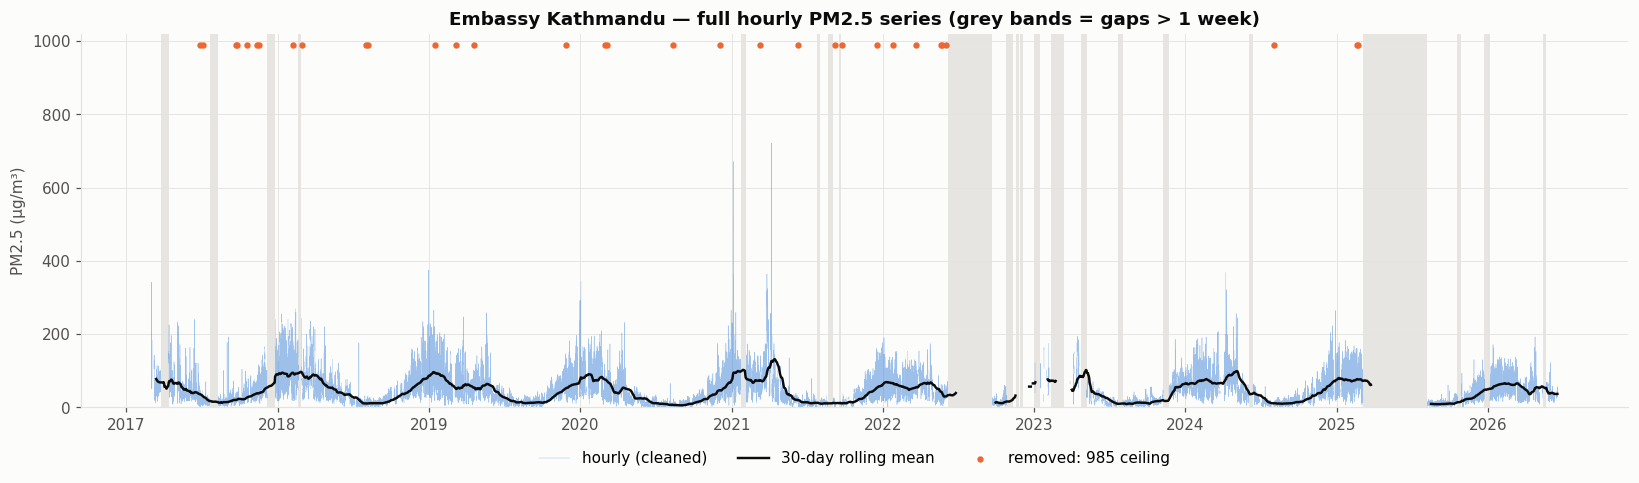

In [13]:
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(emb.index, emb.values, color=BLUE, lw=0.3, alpha=0.45, label="hourly (cleaned)")
daily = emb.resample("D").mean()
ax.plot(daily.index, daily.rolling(30, min_periods=10).mean(), color=INK, lw=1.6, label="30-day rolling mean")
ax.scatter(emb_raw[emb_raw == 985].index, np.full((emb_raw == 985).sum(), 990), s=10, color=ORANGE,
           label="removed: 985 ceiling", zorder=3)
# shade gaps longer than a week
long_gap = emb.isna().astype(int).groupby((emb.notna()).cumsum()).transform("sum")
mask = (emb.isna()) & (long_gap > 24 * 7)
for g, grp in emb[mask].groupby((~mask).cumsum()[mask]):
    ax.axvspan(grp.index[0], grp.index[-1], color=GRID, alpha=0.9, lw=0)
ax.set(title=f"{TARGET_STATION} — full hourly PM2.5 series (grey bands = gaps > 1 week)",
       ylabel="PM2.5 (µg/m³)", ylim=(0, 1020))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout(); plt.show()

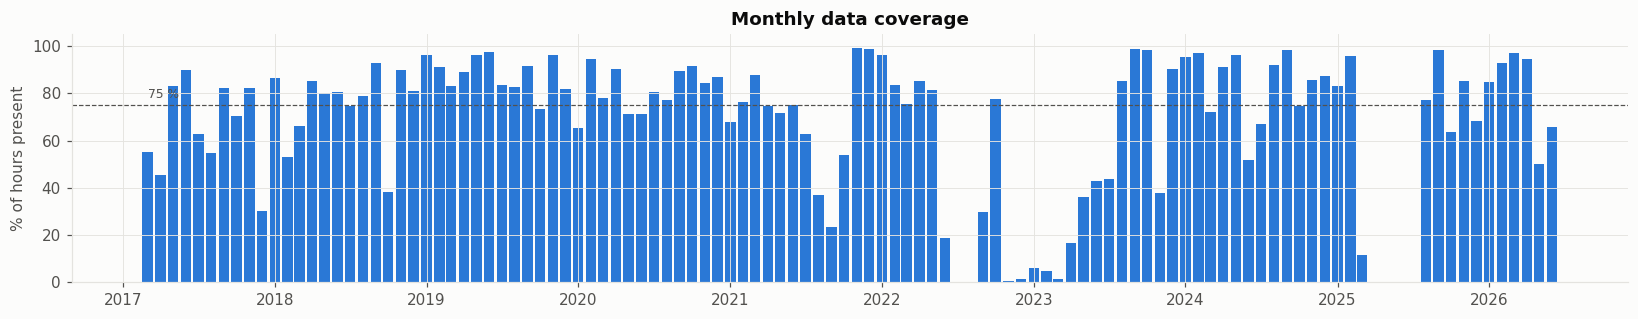

Months with < 50 % coverage: 24 of 112


In [14]:
# Gaps: data coverage per month (100 % = every hour of the month reported)
cov = emb.notna().resample("MS").mean() * 100
fig, ax = plt.subplots(figsize=(15, 3))
ax.bar(cov.index, cov.values, width=25, color=BLUE)
ax.axhline(75, color=INK2, lw=0.8, ls="--"); ax.text(cov.index[0], 78, "75 %", color=INK2, fontsize=8)
ax.set(title="Monthly data coverage", ylabel="% of hours present", ylim=(0, 105))
plt.tight_layout(); plt.show()
print("Months with < 50 % coverage:", int((cov < 50).sum()), "of", len(cov))

In [15]:
# Frequency regularity: spacing between consecutive reported timestamps
dt = emb_raw.dropna().index.to_series().diff().dropna()
step = (dt / pd.Timedelta("1h")).round().astype(int)
reg = step.clip(upper=25).value_counts().sort_index()
reg.index = [f"{i} h" if i < 25 else "≥ 25 h" for i in reg.index]
print(f"{100 * (step == 1).mean():.2f} % of consecutive readings are exactly 1 h apart; "
      f"all timestamps are on the hour: {(emb_raw.dropna().index.minute == 0).all()}")
reg.to_frame("count").T

96.15 % of consecutive readings are exactly 1 h apart; all timestamps are on the hour: True


,1 h,2 h,3 h,4 h,5 h,6 h,7 h,8 h,9 h,10 h,...,16 h,17 h,18 h,19 h,20 h,21 h,22 h,23 h,24 h,≥ 25 h
count,53504,917,485,179,103,60,58,29,24,23,...,6,5,5,8,6,5,2,3,8,142


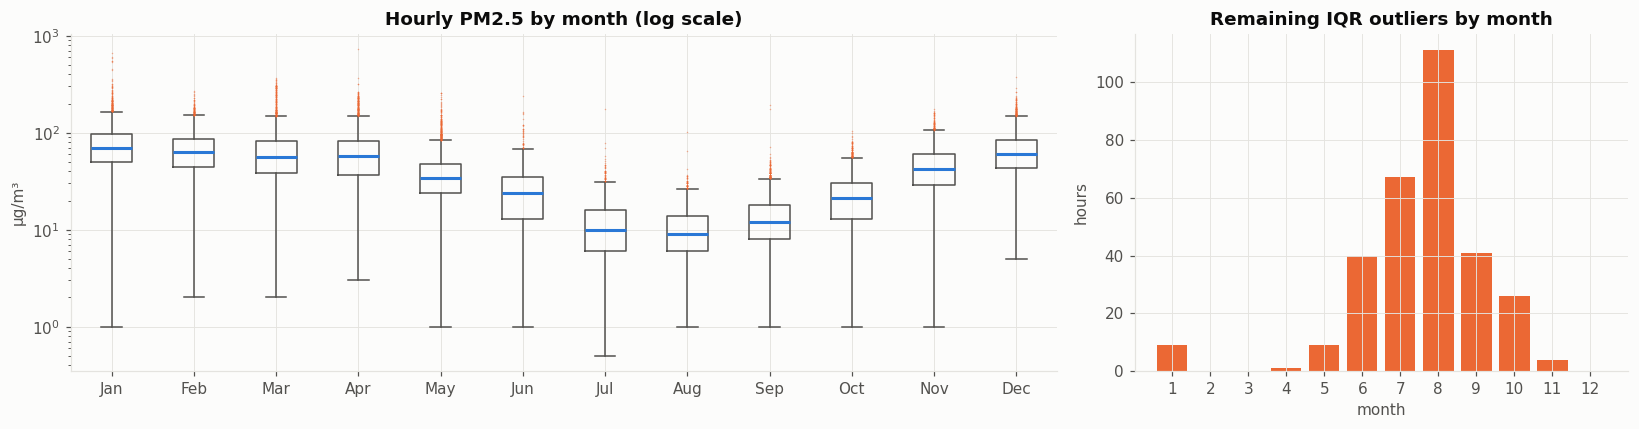

IQR fences on log scale -> [1.4, 430.8] µg/m³; outliers after cleaning: 308 (0.56 %): 299 low, 9 high


In [16]:
# Outliers: by month (log scale shows the whole range) + IQR rule on log values
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})
by_month = [emb.dropna()[emb.dropna().index.month == m].values for m in range(1, 13)]
ax[0].boxplot(by_month, labels=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
              flierprops=dict(marker=".", markersize=2, markerfacecolor=ORANGE, markeredgecolor="none", alpha=.5),
              medianprops=dict(color=BLUE, lw=2), boxprops=dict(color=INK2), whiskerprops=dict(color=INK2),
              capprops=dict(color=INK2))
ax[0].set_yscale("log"); ax[0].set(title="Hourly PM2.5 by month (log scale)", ylabel="µg/m³")

lg = np.log1p(emb.dropna())
q1, q3 = lg.quantile([.25, .75]); iqr = q3 - q1
lo, hi = np.expm1(q1 - 1.5 * iqr), np.expm1(q3 + 1.5 * iqr)
out = emb.dropna()[(emb.dropna() < lo) | (emb.dropna() > hi)]
ax[1].hist(out.index.month, bins=np.arange(.5, 13.5), color=ORANGE, rwidth=.8)
ax[1].set(title="Remaining IQR outliers by month", xlabel="month", ylabel="hours", xticks=range(1, 13))
plt.tight_layout(); plt.show()
print(f"IQR fences on log scale -> [{lo:.1f}, {hi:.1f}] µg/m³; outliers after cleaning: {len(out)} "
      f"({100*len(out)/emb.notna().sum():.2f} %): {int((out < lo).sum())} low, {int((out > hi).sum())} high")

**Observations**
* **Gaps:** about 32 % of hours are missing. 2022, 2023 and 2025 each have under 50 % coverage, with 3 outages longer than a month. Even after bridging 1–3 h gaps, the longest gap-free run is only 67 days (computed in B2). Short gaps of 1–3 h are frequent (about 1,600 of them) and safe to interpolate.
* **Frequency:** every reading is on the hour and 96 % of consecutive readings are exactly 1 h apart. The timestamps themselves are regular. Irregularity only means *missing* steps, never off-grid ones, so reindexing with `asfreq('h')` is enough.
* **Outliers:** after cleaning, about 0.6 % of hours fall outside the log-scale IQR fences. On the log scale, these are almost all **low** values (≤ 1 µg/m³) in the **monsoon** (Jun–Sep), when rain washes the air out. Only a handful of hours exceed the upper fence (about 430 µg/m³). The monthly boxplots show that the high tail (whiskers and points up to several hundred µg/m³) belongs to **winter and pre-monsoon** (inversion layers, wildfire smoke, brick kilns). Both tails are physically plausible, so I keep them. The near-zero monsoon values matter for the log transform, which is why I use `log1p` and not `log`.

## B2. Seasonality, trend decomposition, autocorrelation

Two time scales matter. A single decomposition cannot show both on this gappy series, so there are two:
1. **Annual + trend**: classical decomposition (365-day moving average) on *daily* means, over the longest nearly complete stretch of days (about 3 years).
2. **Daily + weekly**: MSTL on *hourly* values, over the longest contiguous hourly stretch.

Daily decomposition segment: 2018-03-03 → 2021-01-28 (1063 days)


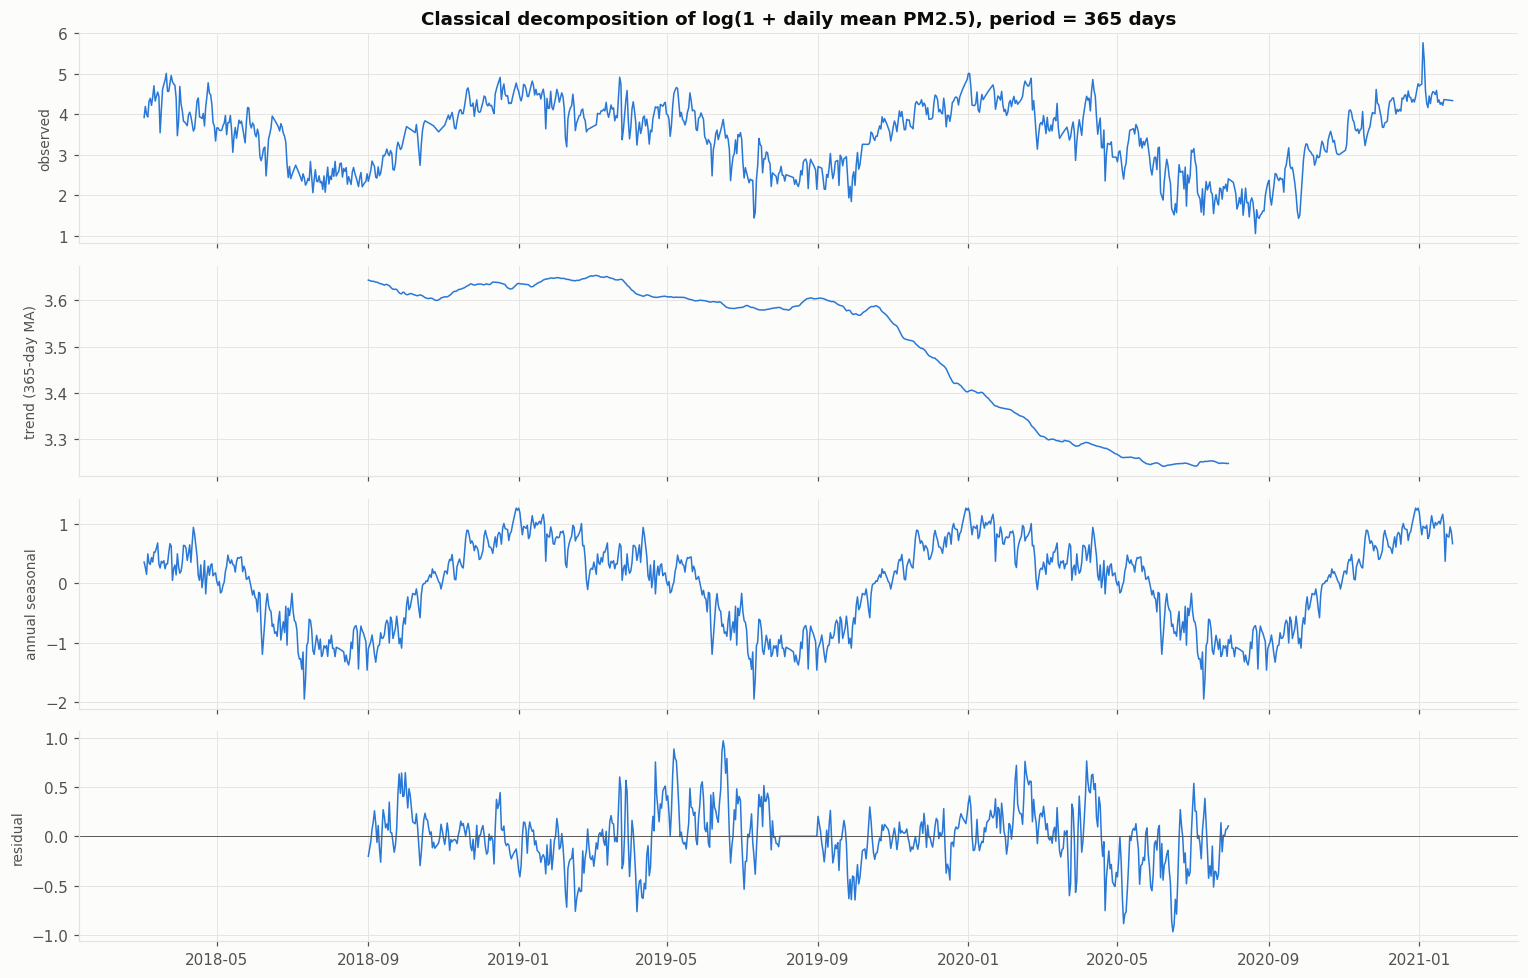

Strength of annual seasonality F_s = 0.86   strength of trend F_t = 0.26   (0 = none, 1 = dominant)


In [17]:
def longest_run(s):
    ok = s.notna()
    rid = (ok != ok.shift()).cumsum()
    runs = s[ok].groupby(rid[ok]).agg(lambda v: len(v))
    best = runs.idxmax()
    idx = s[ok & (rid == best)].index
    return s.loc[idx[0]:idx[-1]]

# daily means; a day counts only if >= 12 of 24 hours are present; bridge gaps up to 7 days
d_cnt = emb.resample("D").count()
d_mean = emb.resample("D").mean().where(d_cnt >= 12)
d_seg = longest_run(d_mean.interpolate(limit=7, limit_area="inside"))
print(f"Daily decomposition segment: {d_seg.index[0].date()} → {d_seg.index[-1].date()} ({len(d_seg)} days)")

# ~3 annual cycles: too few for STL's per-day-of-year smoother (it interpolates them exactly -> zero residual),
# so use the classical decomposition: 365-day centred moving-average trend + averaged annual profile
dec = seasonal_decompose(np.log1p(d_seg), model="additive", period=365)
fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for a, (name, comp) in zip(ax, [("observed", dec.observed), ("trend (365-day MA)", dec.trend),
                                ("annual seasonal", dec.seasonal), ("residual", dec.resid)]):
    a.plot(comp.index, comp.values, color=BLUE, lw=1); a.set_ylabel(name, fontsize=9)
ax[0].set_title("Classical decomposition of log(1 + daily mean PM2.5), period = 365 days")
ax[3].axhline(0, color=INK2, lw=.6)
plt.tight_layout(); plt.show()

var = lambda x: np.nanvar(x)
F_s = max(0, 1 - var(dec.resid) / var(dec.seasonal + dec.resid))
F_t = max(0, 1 - var(dec.resid) / var(dec.trend + dec.resid))
print(f"Strength of annual seasonality F_s = {F_s:.2f}   strength of trend F_t = {F_t:.2f}   (0 = none, 1 = dominant)")

Hourly MSTL segment: 2019-04-13 12:00:00+00:00 → 2019-06-19 15:00:00+00:00 (1,612 h ≈ 67 days)


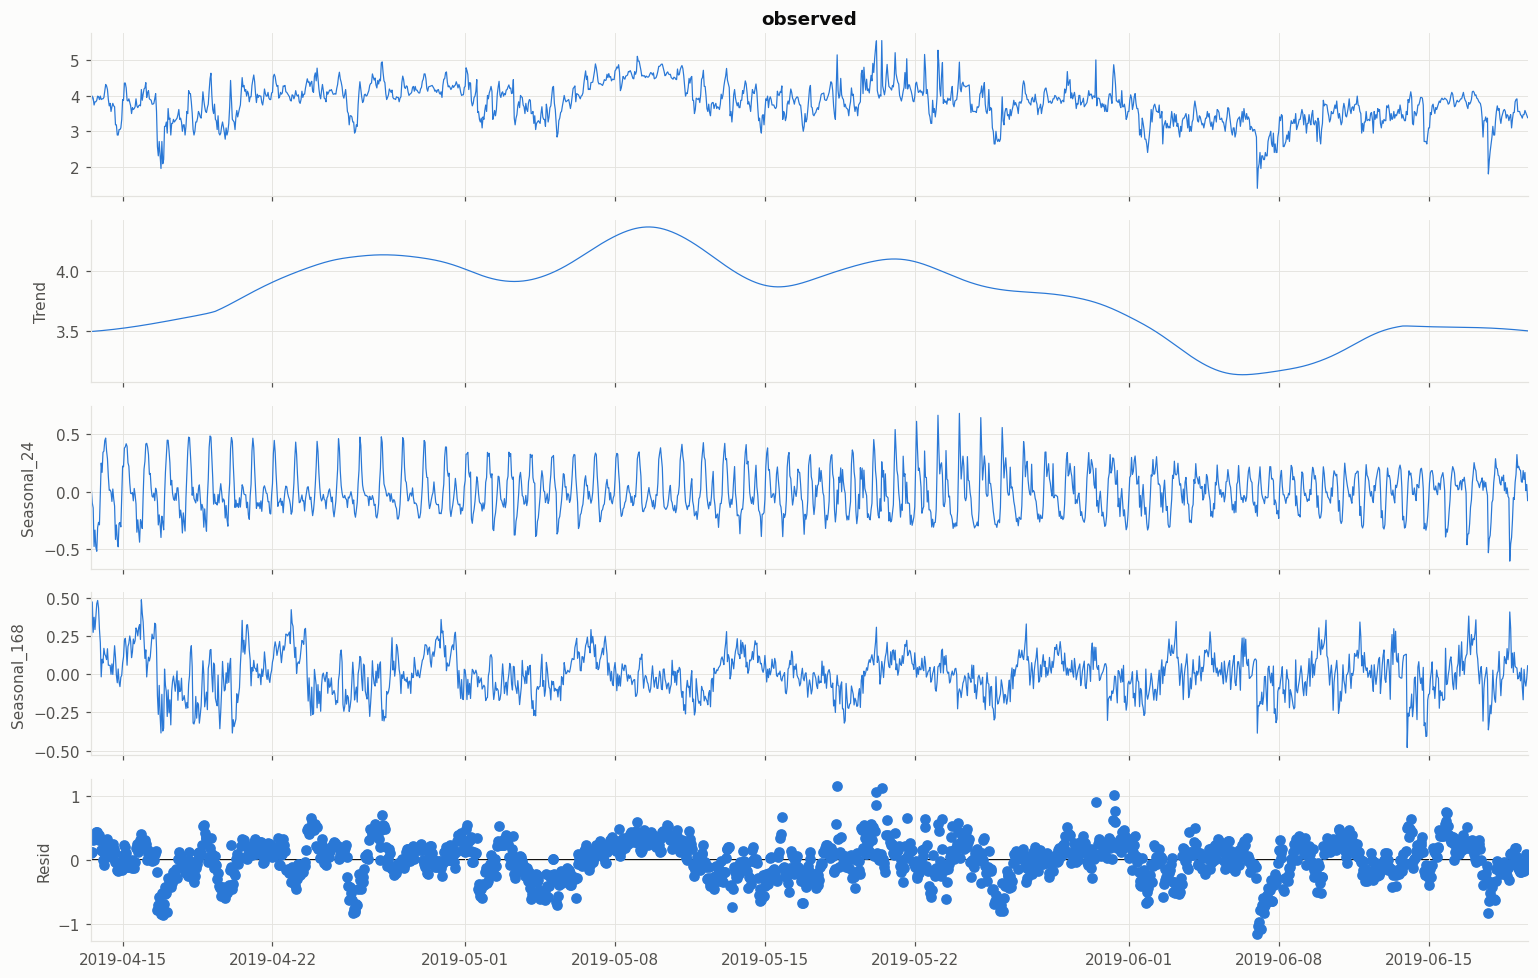

Amplitude (log units): daily = 0.64, weekly = 0.48


In [18]:
# Daily and weekly cycles on the longest hourly segment
h_seg = longest_run(emb_filled)
print(f"Hourly MSTL segment: {h_seg.index[0]} → {h_seg.index[-1]} ({len(h_seg):,} h ≈ {len(h_seg)/24:.0f} days)")

mstl = MSTL(np.log1p(h_seg), periods=(24, 168)).fit()
fig = mstl.plot(); fig.set_size_inches(14, 9)
for a in fig.axes: a.lines[0].set_color(BLUE); a.lines[0].set_linewidth(0.8)
plt.tight_layout(); plt.show()

amp = lambda c: (c.max() - c.min()) / 2
print(f"Amplitude (log units): daily = {amp(mstl.seasonal['seasonal_24']):.2f}, "
      f"weekly = {amp(mstl.seasonal['seasonal_168']):.2f}")

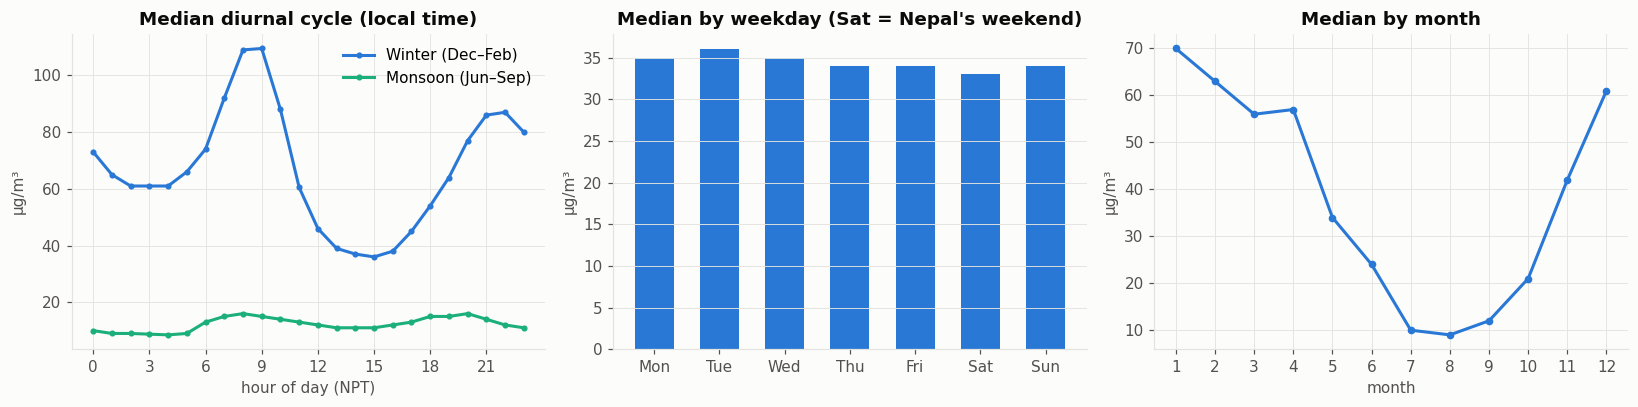

Winter / monsoon median ratio: 5.4×


In [19]:
# Climatology over the whole record, in LOCAL time (Nepal, UTC+05:45)
loc = emb.dropna().tz_convert(NPT)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for season_name, months, col in [("Winter (Dec–Feb)", [12, 1, 2], BLUE),
                                 ("Monsoon (Jun–Sep)", [6, 7, 8, 9], AQUA)]:
    sub = loc[loc.index.month.isin(months)]
    sub.groupby(sub.index.hour).median().plot(ax=ax[0], color=col, lw=2, label=season_name, marker="o", ms=3)
ax[0].set(title="Median diurnal cycle (local time)", xlabel="hour of day (NPT)", ylabel="µg/m³", xticks=range(0, 24, 3))
ax[0].legend()
dow = loc.groupby(loc.index.dayofweek).median()
ax[1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow.values, color=BLUE, width=.6)
ax[1].set(title="Median by weekday (Sat = Nepal's weekend)", ylabel="µg/m³"); ax[1].grid(axis="x", visible=False)
mon = loc.groupby(loc.index.month).median()
ax[2].plot(mon.index, mon.values, color=BLUE, lw=2, marker="o", ms=4)
ax[2].set(title="Median by month", xlabel="month", ylabel="µg/m³", xticks=range(1, 13))
plt.tight_layout(); plt.show()
print(f"Winter / monsoon median ratio: "
      f"{loc[loc.index.month.isin([12,1,2])].median() / loc[loc.index.month.isin([6,7,8,9])].median():.1f}×")

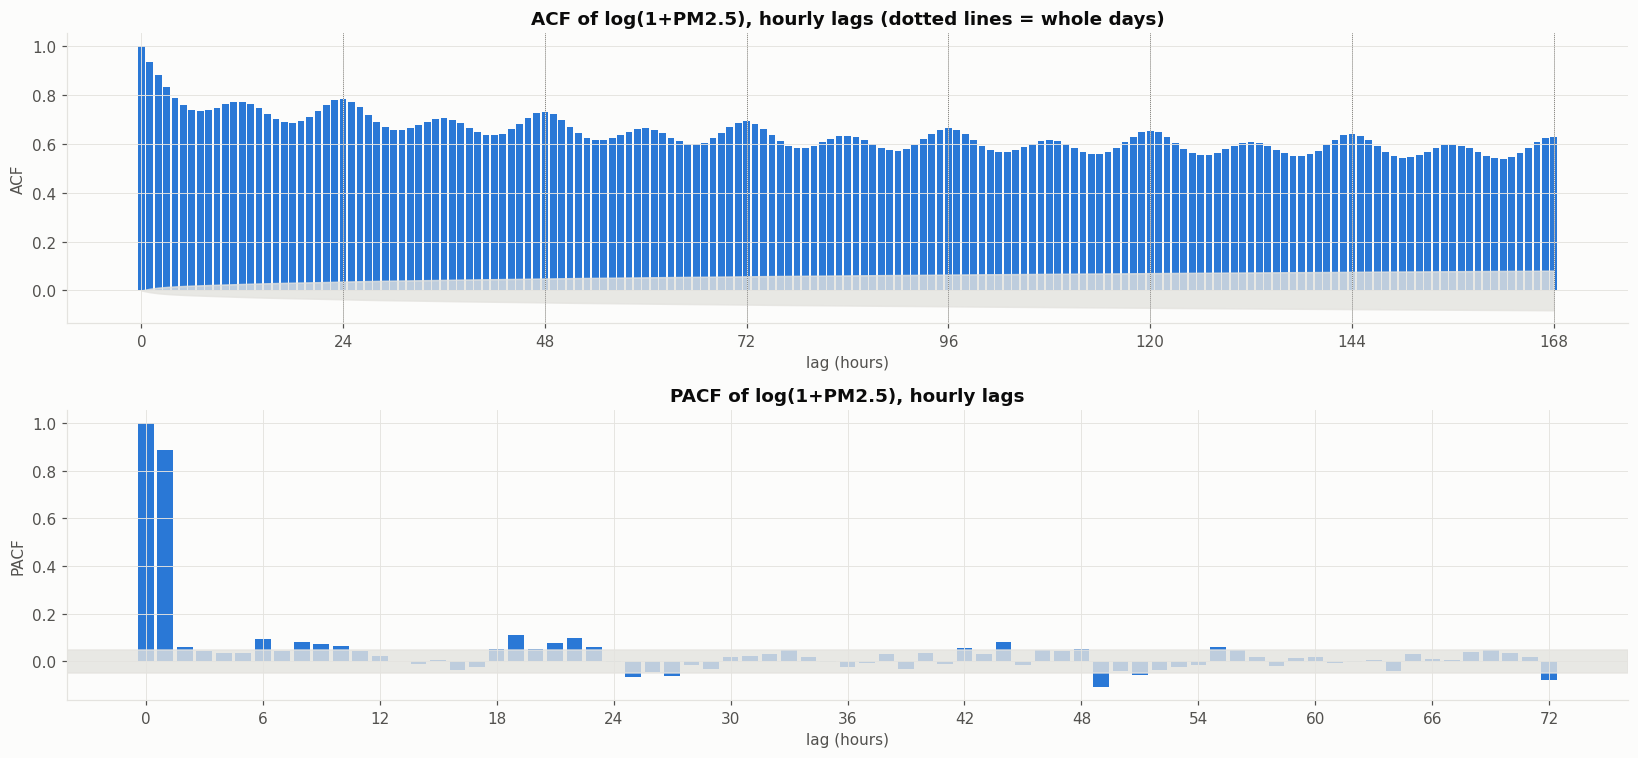

ACF at selected lags: {1: np.float64(0.94), 3: np.float64(0.83), 6: np.float64(0.74), 12: np.float64(0.77), 24: np.float64(0.78), 48: np.float64(0.73), 72: np.float64(0.69), 168: np.float64(0.63)}


In [20]:
# Autocorrelation on the full cleaned hourly series. missing="conservative" uses only real pairs, so gaps don't bias it
LAGS = 24 * 7
y_log = np.log1p(emb_filled)
acf_vals, acf_ci = acf(y_log, nlags=LAGS, missing="conservative", alpha=0.05)
pacf_vals = pacf(np.log1p(h_seg), nlags=72, method="ywm")

fig, ax = plt.subplots(2, 1, figsize=(15, 7))
ax[0].bar(range(LAGS + 1), acf_vals, width=0.8, color=BLUE)
ax[0].fill_between(range(LAGS + 1), acf_ci[:, 0] - acf_vals, acf_ci[:, 1] - acf_vals, color=GRID, alpha=.8)
for d in range(24, LAGS + 1, 24): ax[0].axvline(d, color=INK2, lw=0.5, ls=":")
ax[0].set(title="ACF of log(1+PM2.5), hourly lags (dotted lines = whole days)", xlabel="lag (hours)", ylabel="ACF",
          xticks=range(0, LAGS + 1, 24))
ci = 1.96 / np.sqrt(len(h_seg))
ax[1].bar(range(len(pacf_vals)), pacf_vals, width=0.8, color=BLUE)
ax[1].axhspan(-ci, ci, color=GRID, alpha=.8)
ax[1].set(title="PACF of log(1+PM2.5), hourly lags", xlabel="lag (hours)", ylabel="PACF", xticks=range(0, 73, 6))
plt.tight_layout(); plt.show()

print("ACF at selected lags:", {l: round(acf_vals[l], 2) for l in [1, 3, 6, 12, 24, 48, 72, 168]})

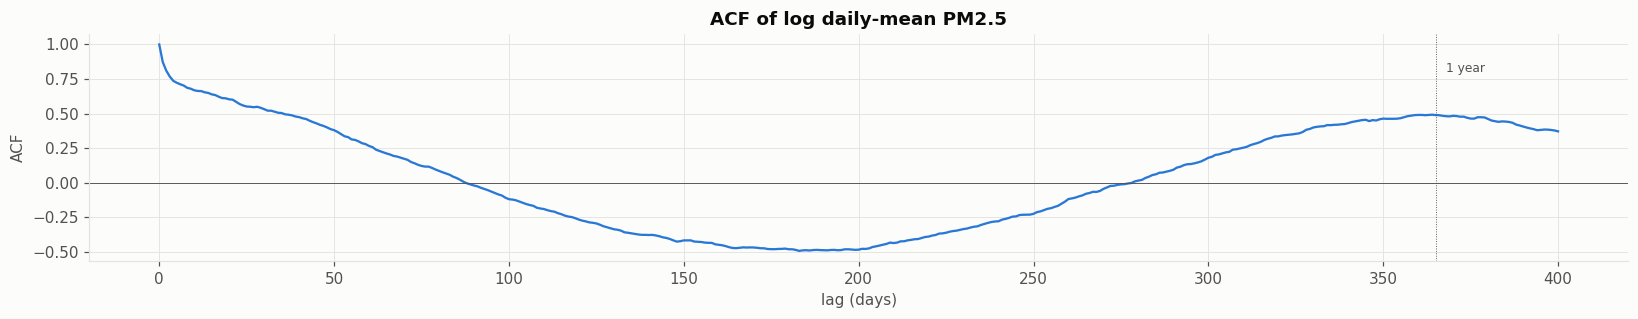

In [21]:
# Long-range ACF on daily means: is there memory beyond a week?
d_acf = acf(np.log1p(d_mean), nlags=400, missing="conservative")
fig, ax = plt.subplots(figsize=(15, 3))
ax.plot(d_acf, color=BLUE, lw=1.5); ax.axhline(0, color=INK2, lw=.6)
ax.axvline(365, color=INK2, lw=.6, ls=":"); ax.text(368, .8, "1 year", color=INK2, fontsize=8)
ax.set(title="ACF of log daily-mean PM2.5", xlabel="lag (days)", ylabel="ACF")
plt.tight_layout(); plt.show()

**Observations**
* **Annual seasonality is the dominant structure** (strength F_s printed above, the larger of the two). The seasonal component swings from a winter maximum to a monsoon minimum, a range of about 2 log units (roughly 7×). Daily ACF falls to negative values around 6 months and rises again near 1 year.
* **Trend** is weak (F_t much smaller than F_s). The 365-day moving average is flat through 2018–19, then drops by about 0.4 log units (≈ 33 % lower) during 2020, the year of the COVID-19 lockdown. The full-series plot shows levels recovering from 2021, so this is an event-driven level shift, not a lasting trend. Annual means are also biased by uneven coverage (2022, 2023 and 2025 each have under 50 % of hours). Annual means are also biased by uneven coverage (2022, 2023 and 2025 each have under 50 % of hours), so I don't read much into them.
* **Daily cycle:** in local time there is a strong double peak, in the morning (08–09 NPT, about 110 µg/m³ in winter) and the evening (21–22 NPT), with a minimum around 14–15 NPT. Peak-to-trough is about 3× in winter (night-time inversion layer traps emissions; afternoon mixing disperses them) but only about 2× in the monsoon.
* **Weekly cycle:** negligible. Weekday medians differ by only about 1–3 µg/m³, and Saturday (Nepal's weekend) is barely lower. The weekly MSTL component has a non-trivial amplitude only because, on a 67-day stretch, it soaks up part of the pre-monsoon → monsoon decline. It is not a real weekly cycle.
* **Autocorrelation:** the ACF decays very slowly (0.94 at 1 h, still about 0.63 at 168 h) and has local bumps at every multiple of 24 h (e.g. 0.77 at 12 h vs 0.78 at 24 h). Slow decay like this is a sign of a non-stationary level. The PACF is dominated by lag 1, with significant clusters around **lags 18–25** and **42–51**, i.e. the same hour one and two days earlier.

## B3. Stationarity — ADF test (with KPSS as a cross-check)

* **ADF:** H₀ = a unit root (non-stationary). A small p-value means stationary.
* **KPSS:** H₀ = stationary. A small p-value means non-stationary.

Using both separates "unit root" from "stationary around a seasonal pattern". Tests run on the longest contiguous hourly stretch (no NaNs) and the gap-bridged multi-year daily series, then on the 6 longest hourly stretches as a robustness check.

In [22]:
def stationarity(x, name, maxlag):
    x = pd.Series(x).dropna()
    adf = adfuller(x, maxlag=maxlag, autolag="AIC")
    kp = kpss(x, regression="c", nlags="auto")
    return {"series": name, "n": len(x), "ADF stat": round(adf[0], 2), "ADF p": round(adf[1], 4),
            "ADF 5% crit": round(adf[4]["5%"], 2), "KPSS stat": round(kp[0], 3), "KPSS p": round(kp[1], 3),
            "ADF says": "stationary" if adf[1] < .05 else "unit root",
            "KPSS says": "stationary" if kp[1] > .05 else "non-stationary"}

hl = np.log1p(h_seg)
dl = np.log1p(d_seg)
res = pd.DataFrame([
    stationarity(h_seg,                "hourly raw",                      48),
    stationarity(hl,                   "hourly log1p",                    48),
    stationarity(hl.diff(24).dropna(), "hourly log1p, seasonal diff 24h", 48),
    stationarity(dl,                   "daily log1p (multi-year)",        30),
    stationarity(dl.diff().dropna(),   "daily log1p, first diff",         30),
    stationarity(dec.resid.dropna(),   "daily log1p, annual seasonal + trend removed", 30),
]).set_index("series")
res

,n,ADF stat,ADF p,ADF 5% crit,KPSS stat,KPSS p,ADF says,KPSS says
series,,,,,,,,
hourly raw,1612,-2.06,0.2614,-2.86,1.570,0.01,unit root,non-stationary
hourly log1p,1612,-2.26,0.1838,-2.86,1.720,0.01,unit root,non-stationary
"hourly log1p, seasonal diff 24h",1588,-5.93,0.0000,-2.86,0.026,0.10,stationary,stationary
daily log1p (multi-year),1063,-2.67,0.0801,-2.86,0.311,0.10,unit root,stationary
"daily log1p, first diff",1062,-15.79,0.0000,-2.86,0.078,0.10,stationary,stationary
"daily log1p, annual seasonal + trend removed",699,-3.43,0.0100,-2.87,0.208,0.10,stationary,stationary


In [23]:
# Robustness: one 67-day stretch can't represent a 9-year record, so repeat ADF on the 6 longest gap-free hourly stretches
ok = emb_filled.notna(); rid = (ok != ok.shift()).cumsum()
top = emb_filled[ok].groupby(rid[ok]).size().sort_values(ascending=False).head(6)
rows = []
for k, n in top.items():
    seg = np.log1p(emb_filled[ok & (rid == k)])
    rows.append({"start": seg.index[0].date(), "hours": n, "mid-month": seg.index[n // 2].strftime("%b"),
                 "ADF p (log1p level)": round(adfuller(seg, maxlag=48, autolag="AIC")[1], 4),
                 "ADF p (log1p, Δ24h)": round(adfuller(seg.diff(24).dropna(), maxlag=48, autolag="AIC")[1], 4)})
seg_adf = pd.DataFrame(rows)
seg_adf["level stationary?"] = seg_adf["ADF p (log1p level)"] < .05
seg_adf["Δ24 stationary?"] = seg_adf["ADF p (log1p, Δ24h)"] < .05
seg_adf

,start,hours,mid-month,ADF p (log1p level),"ADF p (log1p, Δ24h)",level stationary?,Δ24 stationary?
0,2019-04-13,1612,May,0.1838,0.0,False,True
1,2021-10-25,1606,Nov,0.5313,0.0,False,True
2,2025-08-07,1425,Sep,0.0001,0.0,True,True
3,2024-08-01,1362,Aug,0.0065,0.0,True,True
4,2024-04-03,1322,May,0.1851,0.0,False,True
5,2026-02-05,1170,Mar,0.2770,0.0,False,True


**Interpretation and the transformation I will apply**

* **Raw and log1p levels are non-stationary.** On the longest hourly stretch, ADF cannot reject a unit root (p ≈ 0.18) and KPSS rejects stationarity. Across the 6 longest stretches, the level passes ADF in only 2 (both in the monsoon, when the level is flat). The others span a seasonal transition, so their mean drifts. This agrees with the slowly decaying ACF. On the 3-year daily series the result is borderline (ADF p ≈ 0.08, KPSS does not reject). Over whole years the seasonal cycle is mean-reverting, so the non-stationarity the LSTM faces is *local*: inside any few-week window the level drifts with the season.
* **The 24-hour seasonal difference is stationary everywhere.** `Δ24 log1p(y)` = log1p(y_t) − log1p(y_{t−24}) gives ADF p < 0.001 on all 6 stretches, and KPSS does not reject. On the daily series, a first difference does the same.
* **log1p** is still needed for variance. Raw variance grows with the level (winter swings are much larger than monsoon ones), and A4 showed log1p brings the skew from 2.2 to about −0.4.

**Transformation pipeline for the LSTM:**
1. `z = log1p(PM2.5)`, standardised with **train-only** mean/std. This handles scale, skew and heteroscedasticity.
2. **Target = 24-hour seasonal difference** `Δ24 z_{t+1} = z_{t+1} − z_{t−23}`, which both tests show is stationary. The forecast is rebuilt as `ẑ_{t+1} = Δ̂ + z_{t−23}` and then `expm1`. A bonus is that the **seasonal-naive forecast** (Δ̂ = 0, "same as this hour yesterday") becomes the natural baseline the LSTM must beat.
3. The inputs stay on the (standardised) level scale so the network sees the absolute pollution state. **Calendar features** (`sin/cos` hour in local time, `sin/cos` day-of-year) tell it where it is in the annual cycle, which no short window can show.
4. No first differencing at the hourly level. Δ24 already removes the drifting level and the daily cycle, and a further difference would only amplify sensor noise.

## B4. LSTM window length from the ACF

In [24]:
sig = 1.96 / np.sqrt(emb_filled.notna().sum())
first_below = lambda thr: int(np.argmax(acf_vals < thr))
peaks = {d: round(acf_vals[d], 3) for d in (24, 48, 72, 96, 120, 144, 168)}
gain = {f"{a}->{b}h": round(acf_vals[a] - acf_vals[b], 3) for a, b in [(24, 48), (48, 72), (72, 96), (96, 120)]}

for thr in (.75, .5):
    print(f"ACF first drops below {thr}:", f"lag {first_below(thr)} h" if (acf_vals < thr).any() else f"never within {LAGS} h")
print(f"ACF still above the 95% significance band ({sig:.3f}) at lag {LAGS} h: {acf_vals[LAGS] > sig}")
print("ACF at daily peaks:", peaks)
print("Drop in ACF from one daily peak to the next:", gain)
print("PACF > CI at lags:", [l for l in range(1, 73) if abs(pacf_vals[l]) > ci])

# how many training windows are available for candidate W (no NaN inside window + target)?
tr = emb_filled.loc[SPLITS["train"][0]:SPLITS["train"][1]]
ok = tr.notna().astype(int)
for W in (24, 48, 72, 168):
    n = int((ok.rolling(W + 1).sum() == W + 1).sum())
    print(f"W = {W:>3} h -> {n:,} usable training windows")

ACF first drops below 0.75: lag 6 h
ACF first drops below 0.5: never within 168 h
ACF still above the 95% significance band (0.008) at lag 168 h: True
ACF at daily peaks: {24: np.float64(0.785), 48: np.float64(0.732), 72: np.float64(0.693), 96: np.float64(0.666), 120: np.float64(0.655), 144: np.float64(0.642), 168: np.float64(0.63)}
Drop in ACF from one daily peak to the next: {'24->48h': np.float64(0.053), '48->72h': np.float64(0.038), '72->96h': np.float64(0.028), '96->120h': np.float64(0.011)}
PACF > CI at lags: [1, 2, 6, 8, 9, 10, 18, 19, 20, 21, 22, 23, 25, 27, 42, 44, 48, 49, 51, 55, 72]
W =  24 h -> 35,722 usable training windows
W =  48 h -> 30,739 usable training windows
W =  72 h -> 27,049 usable training windows
W = 168 h -> 17,797 usable training windows


**Decision: input window W = 48 hours** (two full daily cycles).

Justification from the ACF and PACF:
1. **Where the information is (PACF).** Beyond the dominant lag 1–2, the significant partial autocorrelations come in two clusters: **lags 18–25** (same hour yesterday) and **lags 42–51** (same hour two days ago). Lag 72 is only borderline. A 48 h window contains both clusters, and 24 h would cut off the second.
2. **The target needs it.** The target is the 24 h seasonal difference (B3), so the value at *t−23* must be inside the window. 48 h also gives the model a full previous day to compare against: is pollution building up (an inversion episode) or clearing?
3. **Daily periodicity (ACF).** The ACF has local peaks at every multiple of 24 h, so the window should be a whole number of days, which gives every hour of the cycle equal representation.
4. **Diminishing returns.** The ACF at the daily peaks falls by 0.053 from 24→48 h, then only 0.038, 0.028 and 0.011 for each further day. The ACF never drops below 0.5 within a week, but that persistence is the slowly varying *seasonal level*, which the calendar features and the LSTM hidden state already supply. It is not hour-level detail that needs a longer raw window.
5. **Gap constraint.** Gap-free training windows: 35.7 k at 24 h, **30.7 k at 48 h** (−14 %), 27.0 k at 72 h, and only 17.8 k at 168 h (−50 %). 48 h keeps most of the data.

I will tune **W ∈ {24, 48, 72}** on the validation year as a sensitivity check, with 48 h as the default.

---
## A6. Three findings that change how I will design the model
*(Item A6 is placed at the end because it draws on the Part B results.)*

In [25]:
# Evidence for the findings
w_mon = (loc[loc.index.month.isin([12,1,2])].median(), loc[loc.index.month.isin([6,7,8,9])].median())
wint = loc[loc.index.month.isin([12, 1, 2])]
diurnal = wint.groupby(wint.index.hour).median()
utc_hour_peak = (diurnal.idxmax() * 60 - 345) // 60 % 24

phora = clean_station(hourly("Phora Durbar Kathman")).reindex(emb.index)
both = pd.concat([emb, phora], axis=1, keys=["emb", "phora"]).dropna()
fillable = (emb.isna() & phora.notna()).sum()

print(f"1) Winter median {w_mon[0]:.0f} vs monsoon median {w_mon[1]:.0f} µg/m³ -> {w_mon[0]/w_mon[1]:.1f}× difference")
print(f"2) Winter diurnal peak at {diurnal.idxmax():02d}:00 NPT (≈ {int(utc_hour_peak):02d}:15 UTC); "
      f"peak/trough ratio {diurnal.max()/diurnal.min():.1f}×")
print(f"3) {100*emb_filled.isna().mean():.0f}% of hours missing; longest gap-free stretch {len(h_seg)/24:.0f} days; "
      f"985-ceiling values {int((emb_raw==985).sum())}")
print(f"   Embassy vs Phora Durbar (same-hour) correlation r = {both.corr().iloc[0,1]:.2f} on {len(both):,} hours; "
      f"Phora could fill {fillable:,} missing Embassy hours")

1) Winter median 65 vs monsoon median 12 µg/m³ -> 5.4× difference
2) Winter diurnal peak at 09:00 NPT (≈ 03:15 UTC); peak/trough ratio 3.0×
3) 27% of hours missing; longest gap-free stretch 67 days; 985-ceiling values 32
   Embassy vs Phora Durbar (same-hour) correlation r = 0.89 on 38,806 hours; Phora could fill 8,402 missing Embassy hours


**Finding 1: The seasonal level shift is larger than any day-to-day signal, and a 48 h window cannot see it.**
The winter median is 65 µg/m³ against 12 µg/m³ in the monsoon, a **5.4×** difference. Annual seasonality dominates the decomposition, and on hourly stretches ADF/KPSS show the level is non-stationary. On the AQI scale, *Good* hours are 36 % of the monsoon but 0.2 % of winter. An LSTM that sees only the last 48 h cannot tell whether a reading of 60 µg/m³ is "low for January" or "extreme for July", and it will lag badly at season transitions (e.g. the monsoon onset in June).
→ **Design change:** add `sin/cos(day-of-year)` as inputs on every time step, use **whole years** for validation and test, and report errors **per season**. I expect the largest errors in the March–April wildfire period and at the monsoon onset.

**Finding 2: Pollution follows local clock time, with a winter-only double daily peak, and the timestamps are in UTC.**
The winter peak falls at 09:00 NPT (= 03:15 UTC) with a second peak at 21–22 NPT. Nepal is UTC+05:45, so the 45-minute offset puts UTC hours out of step with the daily cycle. Peak-to-trough is 3× in winter but about 2× and much lower in absolute terms in the monsoon. The weekday effect is negligible. Hour-of-day features built from raw UTC would be misaligned, and the size of the daily cycle depends on the season.
→ **Design change:** convert to `Asia/Kathmandu` before building `sin/cos(hour)` features. Keep the window a **whole number of days** (48 h) so the daily shape is always fully visible. Season and hour features go in together, so the LSTM can learn their interaction instead of a single average daily shape. **No weekday feature**, because it would add noise without signal.

**Finding 3: The target station's record is fragmented and contains instrument artefacts, but a nearby second reference monitor tracks it closely.**
32 % of hours are missing (27 % after bridging ≤ 3 h gaps), the longest gap-free run is 67 days, and the BAM writes 985 µg/m³ as an error code in every month, including the clean monsoon. Phora Durbar correlates at **r = 0.89** with Embassy over 38.8 k shared hours, and has data for 8.4 k hours that Embassy is missing. Naively concatenating the rows would teach the LSTM false jumps across gaps, and the 985 values would be learned as real extreme peaks.
→ **Design change:** (a) remove 985, zeros and isolated spikes; (b) interpolate only gaps of 3 h or less and build windows **only from gap-free stretches** (or feed a "was-imputed" mask channel); (c) add Phora Durbar's lagged PM2.5 as a **second input channel** (missing → 0 plus a mask). This adds information and recovers windows that would otherwise be lost.

*Also feeding into the design (from A4/B3):* the heavy right tail means the target is modelled on a `log1p` scale with Huber loss, and peak hours (> 55.4 µg/m³) get their own evaluation metric.

---
## Summary of decisions carried into modelling

| Decision | Value |
|---|---|
| Target series | Embassy Kathmandu (reference BAM), hourly PM2.5 |
| Cleaning | 985 / 0 / >1000 / isolated spikes → NaN; interpolate ≤ 3 h gaps only |
| Transform | `log1p` + z-score (train stats); target = **24 h seasonal difference** (ADF + KPSS: stationary) |
| Extra inputs | sin/cos hour (local time), sin/cos day-of-year, Phora Durbar PM2.5 + mask (no weekday feature) |
| Window | **48 h** (tune 24/48/72), only gap-free windows |
| Split | Train 2017–2023 · Val 2024 · Test 2025–Jun 2026, chronological, 48 h embargo |
| Loss / metrics | Huber; RMSE/MAE in µg/m³ overall, per season and per AQI category; baseline = seasonal-naive (same hour yesterday) |